In [4]:
import zipfile
from pathlib import Path

import pandas as pd

TRANSPORTE = Path("../data/raw/transporte")

for z in sorted(TRANSPORTE.glob("gtfs_*.zip")):
    with zipfile.ZipFile(z) as f:
        nombres = f.namelist()
        fechas = []

        cal = [n for n in nombres if n.endswith("calendar.txt")]
        if cal:
            df = pd.read_csv(f.open(cal[0]), dtype=str)
            fechas += [df["start_date"].min(), df["end_date"].max()]

        cal_dates = [n for n in nombres if n.endswith("calendar_dates.txt")]
        if cal_dates:
            df = pd.read_csv(f.open(cal_dates[0]), dtype=str)
            fechas += [df["date"].min(), df["date"].max()]

        rutas = [n for n in nombres if n.endswith("routes.txt")]
        n_rutas = len(pd.read_csv(f.open(rutas[0]))) if rutas else 0

    print(f"{z.name}")
    print(f"   válido de {min(fechas)} a {max(fechas)}  ·  {n_rutas} líneas")
    print(f"   archivos: {nombres[:6]}{' ...' if len(nombres) > 6 else ''}")
    print()

gtfs_cercanias.zip
   válido de 20261120 a 20261219  ·  40 líneas
   archivos: ['agency.txt', 'routes.txt', 'trips.txt', 'calendar.txt', 'stop_times.txt', 'stops.txt'] ...

gtfs_emt.zip
   válido de 20261127 a 20271231  ·  238 líneas
   archivos: ['routes.txt', 'stops.txt', 'trips.txt', 'frequencies.txt', 'calendar_dates.txt', 'calendar.txt'] ...

gtfs_metro.zip
   válido de 20250101 a 20260527  ·  13 líneas
   archivos: ['agency.txt', 'calendar.txt', 'calendar_dates.txt', 'fare_attributes.txt', 'fare_rules.txt', 'feed_info.txt'] ...

gtfs_metro_2026.zip
   válido de 20251231 a 20270526  ·  13 líneas
   archivos: ['agency.txt', 'calendar.txt', 'calendar_dates.txt', 'fare_attributes.txt', 'fare_rules.txt', 'feed_info.txt'] ...

gtfs_metro_ligero.zip
   válido de 20260101 a 20271118  ·  4 líneas
   archivos: ['agency.txt', 'calendar.txt', 'calendar_dates.txt', 'fare_attributes.txt', 'fare_rules.txt', 'feed_info.txt'] ...



In [3]:
import io
import zipfile

DIAS = 364  # 52 semanas: los martes siguen siendo martes

def desplazar(columna):
    fechas = pd.to_datetime(columna, format="%Y%m%d", errors="coerce")
    return (fechas + pd.Timedelta(days=DIAS)).dt.strftime("%Y%m%d")

origen = TRANSPORTE / "gtfs_metro.zip"
destino = TRANSPORTE / "gtfs_metro_2026.zip"

with zipfile.ZipFile(origen) as zin, zipfile.ZipFile(destino, "w", zipfile.ZIP_DEFLATED) as zout:
    for nombre in zin.namelist():
        datos = zin.read(nombre)
        if nombre in ("calendar.txt", "calendar_dates.txt", "feed_info.txt"):
            df = pd.read_csv(io.BytesIO(datos), dtype=str, encoding="utf-8-sig")
            for col in ["start_date", "end_date", "date", "feed_start_date", "feed_end_date"]:
                if col in df.columns:
                    df[col] = desplazar(df[col])
            datos = df.to_csv(index=False).encode("utf-8")
        zout.writestr(nombre, datos)

print("Creado:", destino.name)

Creado: gtfs_metro_2026.zip


In [5]:
import sys
sys.argv.extend(["--max-memory", "8G"])   # límite máximo para Java

import datetime as dt
import r5py
print("r5py", r5py.__version__)

r5py 1.1.7


In [6]:
network = r5py.TransportNetwork(
    TRANSPORTE / "madrid-261127.osm.pbf",
    [
        TRANSPORTE / "gtfs_metro_2026.zip",
        TRANSPORTE / "gtfs_metro_ligero.zip",
        TRANSPORTE / "gtfs_cercanias.zip",
        TRANSPORTE / "gtfs_emt.zip",
    ],
)
print("Red construida")

GtfsFileError: Could not load GTFS file gtfs_metro_2026.zip. 
EmptyTableError: fare_attributes line 0: Table is present in zip file, but it has no entries.
- EmptyTableError: fare_rules line 0: Table is present in zip file, but it has no entries.

In [ ]:
import geopandas as gpd
from shapely.geometry import Point

origen = gpd.GeoDataFrame(
    {"id": ["Sol"]},
    geometry=[Point(-3.7035, 40.4169)],
    crs=4326,
)
destinos = gpd.GeoDataFrame(
    {"id": ["Nuevos Ministerios", "Las Tablas", "Atocha", "Aeropuerto T4"]},
    geometry=[
        Point(-3.6920, 40.4466),
        Point(-3.6700, 40.5050),
        Point(-3.6895, 40.4065),
        Point(-3.5930, 40.4910),
    ],
    crs=4326,
)

prueba = r5py.TravelTimeMatrix(
    network,
    origins=origen,
    destinations=destinos,
    departure=dt.datetime(2026, 12, 1, 8, 30),
    transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
    max_time=dt.timedelta(minutes=120),
)
prueba

In [8]:
import os

# Dónde guarda r5py su caché
try:
    from r5py.util import Config
    print("Caché según r5py:", Config().CACHE_DIR)
except Exception as e:
    print("No se pudo leer la configuración:", e)

local = Path(os.environ["LOCALAPPDATA"])
print("Carpetas con 'r5' en AppData\\Local:", [p.name for p in local.iterdir() if "r5" in p.name.lower()])

# Construir la red mostrando el error completo si falla
try:
    network = r5py.TransportNetwork(
        TRANSPORTE / "madrid-261127.osm.pbf",
        [
            TRANSPORTE / "gtfs_metro_2026.zip",
            TRANSPORTE / "gtfs_metro_ligero.zip",
            TRANSPORTE / "gtfs_cercanias.zip",
            TRANSPORTE / "gtfs_emt.zip",
        ],
    )
    print("Red construida")
except Exception as e:
    print("ERROR:", type(e).__name__)
    print(e)
    if hasattr(e, "stacktrace"):
        print(e.stacktrace()[:3000])

Caché según r5py: C:\Users\Usuario\AppData\Local\r5py
Carpetas con 'r5' en AppData\Local: ['r5py']
ERROR: java.io.IOError
java.io.IOError: java.io.IOException: Wrong index checksum, store was not closed properly and could be corrupted.
java.io.IOError: java.io.IOException: Wrong index checksum, store was not closed properly and could be corrupted.
	at org.mapdb.StoreDirect.checkHeaders(StoreDirect.java:269)
	at org.mapdb.StoreDirect.<init>(StoreDirect.java:207)
	at org.mapdb.DBMaker.extendStoreDirect(DBMaker.java:971)
	at org.mapdb.DBMaker.makeEngine(DBMaker.java:758)
	at org.mapdb.DBMaker.make(DBMaker.java:701)
	at com.conveyal.osmlib.OSM.<init>(OSM.java:112)
Caused by: java.io.IOException: Wrong index checksum, store was not closed properly and could be corrupted.
	... 6 more



In [2]:
# ---------- 1. Borrar la caché de r5py (antes de cargar r5py) ----------
import os
import shutil
import io
import zipfile
from pathlib import Path

import pandas as pd

cache = Path(os.environ["LOCALAPPDATA"]) / "r5py"
shutil.rmtree(cache, ignore_errors=True)
print("Caché borrada:", not cache.exists())

TRANSPORTE = Path("../data/raw/transporte")
for f in TRANSPORTE.glob("*.mapdb*"):
    f.unlink()

# ---------- 2. Crear copias limpias de los GTFS ----------
def desplazar(columna, dias):
    fechas = pd.to_datetime(columna, format="%Y%m%d", errors="coerce")
    return (fechas + pd.Timedelta(days=dias)).dt.strftime("%Y%m%d")

def limpiar_gtfs(origen, destino, dias=0):
    quitados = []
    with zipfile.ZipFile(origen) as zin, zipfile.ZipFile(destino, "w", zipfile.ZIP_DEFLATED) as zout:
        for nombre in zin.namelist():
            datos = zin.read(nombre)
            # Tabla vacía (solo cabecera o nada): se quita
            if len(datos.strip().splitlines()) <= 1:
                quitados.append(nombre)
                continue
            # Mover fechas si hace falta
            if dias and nombre in ("calendar.txt", "calendar_dates.txt", "feed_info.txt"):
                df = pd.read_csv(io.BytesIO(datos), dtype=str, encoding="utf-8-sig")
                for col in ["start_date", "end_date", "date", "feed_start_date", "feed_end_date"]:
                    if col in df.columns:
                        df[col] = desplazar(df[col], dias)
                datos = df.to_csv(index=False).encode("utf-8")
            zout.writestr(nombre, datos)
    print(f"{destino.name}: quitadas tablas vacías {quitados}")

LIMPIOS = TRANSPORTE / "limpios"
LIMPIOS.mkdir(exist_ok=True)

limpiar_gtfs(TRANSPORTE / "gtfs_metro.zip",        LIMPIOS / "gtfs_metro_2026.zip", dias=364)
limpiar_gtfs(TRANSPORTE / "gtfs_metro_ligero.zip", LIMPIOS / "gtfs_metro_ligero.zip")
limpiar_gtfs(TRANSPORTE / "gtfs_cercanias.zip",    LIMPIOS / "gtfs_cercanias.zip")
limpiar_gtfs(TRANSPORTE / "gtfs_emt.zip",          LIMPIOS / "gtfs_emt.zip")

# ---------- 3. Configurar memoria y cargar r5py ----------
import sys
sys.argv.extend(["--max-memory", "8G"])

import datetime as dt
import r5py
print("r5py", r5py.__version__)

# ---------- 4. Construir la red (tarda varios minutos, NO interrumpir) ----------
print("Construyendo la red... paciencia, no pares la celda")
try:
    network = r5py.TransportNetwork(
        TRANSPORTE / "madrid-261127.osm.pbf",
        [
            LIMPIOS / "gtfs_metro_2026.zip",
            LIMPIOS / "gtfs_metro_ligero.zip",
            LIMPIOS / "gtfs_cercanias.zip",
            LIMPIOS / "gtfs_emt.zip",
        ],
    )
    print("✅ Red construida")
except Exception as e:
    print("ERROR:", type(e).__name__)
    print(e)
    if hasattr(e, "stacktrace"):
        print(e.stacktrace()[:3000])

Caché borrada: False
gtfs_metro_2026.zip: quitadas tablas vacías ['fare_attributes.txt', 'fare_rules.txt']
gtfs_metro_ligero.zip: quitadas tablas vacías ['fare_attributes.txt', 'fare_rules.txt', 'frequencies.txt']
gtfs_cercanias.zip: quitadas tablas vacías []
gtfs_emt.zip: quitadas tablas vacías []
r5py 1.1.7
Construyendo la red... paciencia, no pares la celda
✅ Red construida


In [3]:
import geopandas as gpd
from shapely.geometry import Point

origen = gpd.GeoDataFrame(
    {"id": ["Sol"]},
    geometry=[Point(-3.7035, 40.4169)],
    crs=4326,
)
destinos = gpd.GeoDataFrame(
    {"id": ["Nuevos Ministerios", "Atocha", "Las Tablas", "Aeropuerto T4"]},
    geometry=[
        Point(-3.6920, 40.4466),
        Point(-3.6895, 40.4065),
        Point(-3.6700, 40.5050),
        Point(-3.5930, 40.4910),
    ],
    crs=4326,
)

prueba = r5py.TravelTimeMatrix(
    network,
    origins=origen,
    destinations=destinos,
    departure=dt.datetime(2026, 12, 1, 8, 30),
    transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
    max_time=dt.timedelta(minutes=120),
)
prueba

,from_id,to_id,travel_time
0,Sol,Nuevos Ministerios,9
1,Sol,Atocha,12
2,Sol,Las Tablas,43
3,Sol,Aeropuerto T4,35


In [4]:
import numpy as np

PROCESSED = Path("../data/processed")
barrios = gpd.read_parquet(PROCESSED / "barrios.parquet")
secciones = gpd.read_parquet(PROCESSED / "secciones.parquet")

# Rejilla de destinos: un punto cada 500 m dentro de Madrid
madrid = barrios.union_all()
xmin, ymin, xmax, ymax = madrid.bounds
xs, ys = np.meshgrid(np.arange(xmin, xmax, 500), np.arange(ymin, ymax, 500))
rejilla = gpd.GeoDataFrame(geometry=gpd.points_from_xy(xs.ravel(), ys.ravel()), crs=barrios.crs)
rejilla = rejilla[rejilla.within(madrid)].reset_index(drop=True)
rejilla["id"] = rejilla.index
print("Puntos de la rejilla:", len(rejilla))

# Orígenes: un punto dentro de cada sección censal
origenes = secciones[["cod_seccion_ine"]].copy()
origenes["geometry"] = secciones.representative_point()
origenes = gpd.GeoDataFrame(origenes, crs=secciones.crs).rename(columns={"cod_seccion_ine": "id"})
print("Orígenes:", len(origenes))

# r5py trabaja en latitud/longitud
rejilla_4326 = rejilla.to_crs(4326)[["id", "geometry"]]
origenes_4326 = origenes.to_crs(4326)[["id", "geometry"]]

Puntos de la rejilla: 2424
Orígenes: 2462


In [5]:
import time

inicio = time.time()
muestra = r5py.TravelTimeMatrix(
    network,
    origins=origenes_4326.sample(100, random_state=42),
    destinations=rejilla_4326,
    departure=dt.datetime(2026, 12, 1, 8, 30),
    transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
    max_time=dt.timedelta(minutes=120),
)
segundos = time.time() - inicio

print(f"100 orígenes: {segundos:.0f} s")
print(f"Estimación para los {len(origenes)}: {segundos * len(origenes) / 100 / 60:.0f} minutos")
print(f"Trayectos sin tiempo (más de 2 h o inalcanzables): {muestra['travel_time'].isna().mean():.1%}")
muestra.describe()

100 orígenes: 688 s
Estimación para los 2462: 282 minutos
Trayectos sin tiempo (más de 2 h o inalcanzables): 35.0%


,to_id,travel_time
count,242400.00000,157620.000000
mean,1211.50000,60.432483
std,699.74991,21.481102
min,0.00000,0.000000
25%,605.75000,45.000000
50%,1211.50000,59.000000
75%,1817.25000,75.000000
max,2423.00000,178.000000


In [7]:
# --- Destinos: solo puntos de la rejilla con actividad a menos de 500 m ---
pois = gpd.read_parquet(PROCESSED / "pois.parquet").to_crs(rejilla.crs)
cerca = gpd.sjoin_nearest(rejilla, pois[["geometry"]], max_distance=500, how="inner")
rejilla_util = rejilla.loc[cerca.index.unique()].reset_index(drop=True)
rejilla_util["id"] = rejilla_util.index
print(f"Rejilla: {len(rejilla)} puntos → {len(rejilla_util)} con actividad cerca")

# --- Orígenes: hasta 5 secciones por barrio (barajamos y cogemos las 5 primeras) ---
seleccion = (
    secciones.sample(frac=1, random_state=42)
    .groupby("cod_barrio")
    .head(5)
)
origenes_sel = gpd.GeoDataFrame(
    {"id": seleccion["cod_seccion_ine"].values,
     "cod_barrio": seleccion["cod_barrio"].values},
    geometry=seleccion.representative_point().values,
    crs=secciones.crs,
)
print(f"Orígenes: {len(origenes_sel)} secciones de {origenes_sel['cod_barrio'].nunique()} barrios")

rejilla_util_4326 = rejilla_util.to_crs(4326)[["id", "geometry"]]
origenes_sel_4326 = origenes_sel.to_crs(4326)[["id", "geometry"]]

# Guardamos la rejilla y los orígenes elegidos, que los necesitaremos después
rejilla_util.to_crs(4326).to_parquet(PROCESSED / "rejilla_destinos.parquet")
origenes_sel.to_parquet(PROCESSED / "origenes_tiempos.parquet")

Rejilla: 2424 puntos → 1333 con actividad cerca
Orígenes: 632 secciones de 131 barrios


In [8]:
import time

PARTES = Path("../data/interim/tiempos")
PARTES.mkdir(parents=True, exist_ok=True)

TAM = 50
bloques = [origenes_sel_4326.iloc[i:i + TAM] for i in range(0, len(origenes_sel_4326), TAM)]
inicio = time.time()

for n, bloque in enumerate(bloques):
    archivo = PARTES / f"parte_{n:03d}.parquet"
    if archivo.exists():
        print(f"Bloque {n + 1}/{len(bloques)} ya calculado, lo salto")
        continue

    t0 = time.time()
    ttm = r5py.TravelTimeMatrix(
        network,
        origins=bloque,
        destinations=rejilla_util_4326,
        departure=dt.datetime(2026, 12, 1, 8, 30),
        departure_time_window=dt.timedelta(minutes=5),
        transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
        max_time=dt.timedelta(minutes=90),
    )
    pd.DataFrame(ttm).to_parquet(archivo)

    hecho = time.time() - inicio
    print(f"Bloque {n + 1}/{len(bloques)} en {time.time() - t0:.0f} s · llevamos {hecho / 60:.0f} min")

print("✅ Cálculo terminado")

Bloque 1/13 en 274 s · llevamos 5 min
Bloque 2/13 en 250 s · llevamos 9 min
Bloque 3/13 en 242 s · llevamos 13 min
Bloque 4/13 en 214 s · llevamos 16 min
Bloque 5/13 en 217 s · llevamos 20 min
Bloque 6/13 en 203 s · llevamos 23 min
Bloque 7/13 en 208 s · llevamos 27 min
Bloque 8/13 en 207 s · llevamos 30 min
Bloque 9/13 en 511 s · llevamos 39 min
Bloque 10/13 en 601 s · llevamos 49 min
Bloque 11/13 en 606 s · llevamos 59 min
Bloque 12/13 en 510 s · llevamos 67 min
Bloque 13/13 en 348 s · llevamos 73 min
✅ Cálculo terminado


In [9]:
partes = sorted(PARTES.glob("parte_*.parquet"))
tiempos = pd.concat([pd.read_parquet(p) for p in partes], ignore_index=True)
print(f"Trayectos calculados: {len(tiempos):,}")
print(f"Sin tiempo (más de 90 min o inalcanzables): {tiempos['travel_time'].isna().mean():.1%}")

# A qué barrio pertenece cada origen
origenes_sel = gpd.read_parquet(PROCESSED / "origenes_tiempos.parquet")
tiempos = tiempos.merge(
    origenes_sel[["id", "cod_barrio"]].rename(columns={"id": "from_id"}),
    on="from_id",
)

# Tiempo típico de cada barrio a cada punto: la mediana de sus secciones
tiempos_barrio = (
    tiempos.groupby(["cod_barrio", "to_id"])["travel_time"]
    .median()
    .round()
    .reset_index()
    .rename(columns={"to_id": "id_destino", "travel_time": "minutos"})
)
tiempos_barrio.to_parquet(PROCESSED / "tiempos_barrio.parquet")

print(f"Tabla final: {len(tiempos_barrio):,} filas "
      f"({tiempos_barrio['cod_barrio'].nunique()} barrios × {tiempos_barrio['id_destino'].nunique()} destinos)")
print(f"Tamaño: {(PROCESSED / 'tiempos_barrio.parquet').stat().st_size / 1e6:.1f} MB")

Trayectos calculados: 842,456
Sin tiempo (más de 90 min o inalcanzables): 8.5%
Tabla final: 174,623 filas (131 barrios × 1333 destinos)
Tamaño: 0.4 MB


In [10]:
rejilla_dest = gpd.read_parquet(PROCESSED / "rejilla_destinos.parquet")
barrios_ll = barrios.to_crs(4326)

def minutos_hasta(lat, lon):
    punto = gpd.GeoDataFrame(geometry=[Point(lon, lat)], crs=4326).to_crs(25830)
    rej = rejilla_dest.to_crs(25830)
    id_cercano = rej.distance(punto.geometry.iloc[0]).idxmin()
    destino = rejilla_dest.loc[id_cercano, "id"]
    t = tiempos_barrio[tiempos_barrio["id_destino"] == destino][["cod_barrio", "minutos"]]
    return barrios_ll.merge(t, on="cod_barrio", how="left")

# Prueba: hasta Nuevos Ministerios
nm = minutos_hasta(40.4466, -3.6920)
print("Más cerca de Nuevos Ministerios:")
print(nm.nsmallest(5, "minutos")[["barrio", "distrito", "minutos"]].to_string(index=False))
print("\nMás lejos:")
print(nm.nlargest(5, "minutos")[["barrio", "distrito", "minutos"]].to_string(index=False))

Más cerca de Nuevos Ministerios:
        barrio  distrito  minutos
    Ríos Rosas  Chamberí     10.0
Cuatro Caminos    Tetuán     12.0
         Lista Salamanca     14.0
       El Viso Chamartín     14.0
 Bellas Vistas    Tetuán     14.0

Más lejos:
        barrio              distrito  minutos
  El Cañaveral             Vicálvaro     61.0
    Aeropuerto               Barajas     59.0
    El Plantío     Moncloa - Aravaca     50.0
      El Pardo Fuencarral - El Pardo     49.0
Cuatro Vientos                Latina     48.0


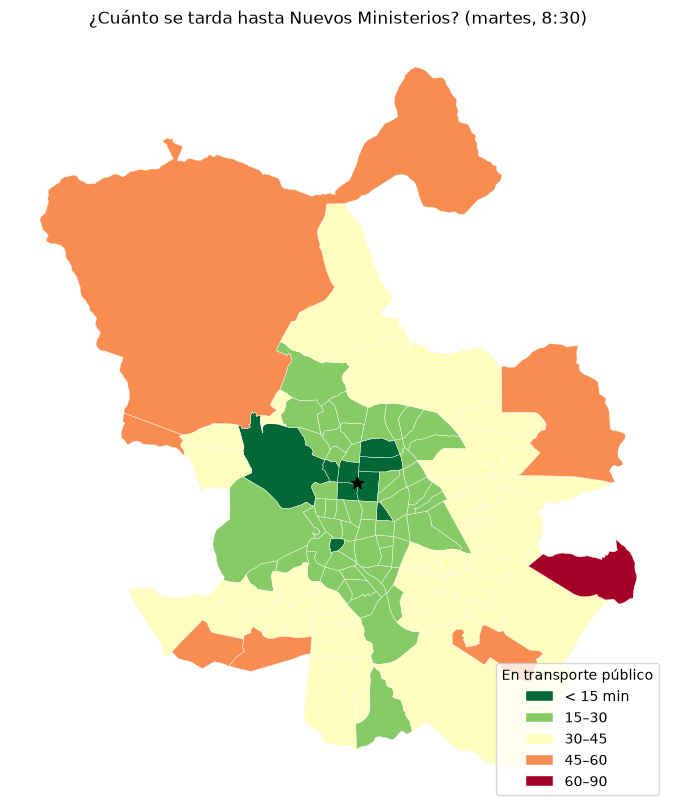

In [11]:
import matplotlib.pyplot as plt

franjas = [0, 15, 30, 45, 60, 90]
etiquetas = ["< 15 min", "15–30", "30–45", "45–60", "60–90"]
nm["franja"] = pd.cut(nm["minutos"], bins=franjas, labels=etiquetas)

fig, ax = plt.subplots(figsize=(10, 10))
nm.plot(ax=ax, color="#dddddd", edgecolor="white", linewidth=0.3)   # más de 90 min
nm.dropna(subset=["franja"]).plot(
    ax=ax, column="franja", cmap="RdYlGn_r", legend=True,
    edgecolor="white", linewidth=0.3,
    legend_kwds={"title": "En transporte público", "loc": "lower right"},
)
gpd.GeoSeries([Point(-3.6920, 40.4466)], crs=4326).plot(ax=ax, color="black", markersize=80, marker="*")
ax.set_axis_off()
ax.set_title("¿Cuánto se tarda hasta Nuevos Ministerios? (martes, 8:30)")
plt.savefig("../data/interim/isocrona_nuevos_ministerios.png", dpi=150, bbox_inches="tight")